In [9]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

CODE_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

SCRIPTS_DIR = CODE_DIR / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from environments.gridworld import GridNavi
from detect import Detect

from plotting import heatmap, annotate_heatmap

ACTION_NAMES = {0: "noop", 1: "up", 2: "right", 3: "down", 4: "left"}

In [2]:
import time
from IPython.display import clear_output

PAUSE_SEC = 0.5  # seconds between frames; set to 0 for no pause
N = 128  # number of tuples to collect for the embedding dataset
NUM_CELLS = 10  # side of grid
MAX_STEPS = 5  # enough steps to cross a 10x10 grid

def show_step(env, title, footer=""):
    clear_output(wait=True)
    frame = env.render()
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(frame)
    ax.axis("off")
    ax.set_title(title)
    plt.show()
    plt.close(fig)
    print(title)
    if footer:
        print(footer)

def run_test(env, viz=False):
    obs = env.reset()
    goal = tuple(env.get_task().astype(int))
    total_reward = 0.0

    if viz:
        show_step(
            env,
            f"start | pos={obs}",
            footer=f"Goal: {goal} | max steps: {env._max_episode_steps}",
        )
        time.sleep(PAUSE_SEC)

    for step in range(env._max_episode_steps):
        action = env.action_space.sample()
        obs, reward, done, info = env.step(action)
        total_reward += reward

        if viz:
            show_step(
                env,
                f"step {step + 1} | {ACTION_NAMES[int(action)]:5s} | "
                f"pos={obs} | reward={reward:+.2f} | done={done}",
                footer=f"Goal: {goal} | return so far: {total_reward:.2f}",
            )
            time.sleep(PAUSE_SEC)

        if done:
            break

    print("-" * 40)
    print(f"Goal:           {goal}")
    print(f"Episode return: {total_reward:.2f}")
    print(f"Final position: {tuple(obs.astype(int))}")

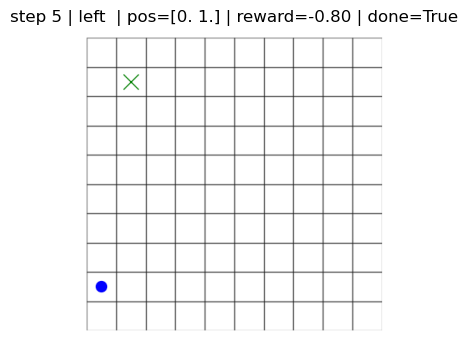

step 5 | left  | pos=[0. 1.] | reward=-0.80 | done=True
Goal: (np.int64(1), np.int64(8)) | return so far: -4.10
----------------------------------------
Goal:           (np.int64(1), np.int64(8))
Episode return: -4.10
Final position: (np.int64(0), np.int64(1))


In [42]:
env = GridNavi(num_cells=NUM_CELLS, num_steps=MAX_STEPS, starting_state=(0.0, 0.0), distance_reward=True)

run_test(env, viz=True)

In [6]:
# defining one task distribution by defining an array of possible goals -

def goal_positions(option, NUM_CELLS):
    if option == 1:
        # 4 goal choices, all in top right corner
        pos = [(NUM_CELLS-1, NUM_CELLS-1), (NUM_CELLS-1, NUM_CELLS-2), (NUM_CELLS-2, NUM_CELLS-1), (NUM_CELLS-2, NUM_CELLS-2)]
    elif option == 2:
        # slightly more spread out
        pos = [(NUM_CELLS//2, NUM_CELLS//2), (NUM_CELLS-1, NUM_CELLS//2), (NUM_CELLS//2, NUM_CELLS-1), (NUM_CELLS-1, NUM_CELLS-1)]
    elif option == 3:
        # goals are all 4 corners
        pos = [(0, 0), (0, NUM_CELLS-1), (NUM_CELLS-1, 0), (NUM_CELLS-1, NUM_CELLS-1)]
    return pos

In [ ]:
N = 256
MAX_STEPS = 30

task_dist1 = goal_positions(1, NUM_CELLS)
task_dist2 = goal_positions(2, NUM_CELLS)
task_dist3 = goal_positions(3, NUM_CELLS)

for i, task_dist in enumerate([task_dist1, task_dist2, task_dist3]):
    OUT_DIR = CODE_DIR / "data" / f"task_dist{i+1}"
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    env = GridNavi(
        num_cells=NUM_CELLS,
        num_steps=MAX_STEPS,
        distance_reward=True,
        possible_goals=task_dist,
    )

    for task in task_dist:
        env.reset_task(task=task)
        obs = env.reset()

        sar_rows = []
        while len(sar_rows) < N:
            action = int(env.action_space.sample())
            next_obs, reward, done, info = env.step(action)
            sar_rows.append([obs[0], obs[1], action, reward])
            obs = next_obs
            if done:
                obs = env.reset()

        sar = np.array(sar_rows[:N])  # (N, 4): [x, y, action, reward]
        np.save(OUT_DIR / f"goal_{task[0]}_{task[1]}.npy", sar)
        # print(f"saved goal_{task[0]}_{task[1]}.npy  shape={sar.shape}")


In [8]:
# WTE embedding test for one saved task
OBS_DIM = 2
ACTION_DIM = 5
REFERENCE_NUM = 100
VIZ = False

detect = Detect(
        reference_num=REFERENCE_NUM,
        input_dim=OBS_DIM,
        action_dim=ACTION_DIM,
        num_samples=N,
    )
detect.set_reference(OBS_DIM, REFERENCE_NUM, ACTION_DIM)

mean_dists = []
for i, task_dist in enumerate([task_dist1, task_dist2, task_dist3]):
    OUT_DIR = CODE_DIR / "data" / f"task_dist{i+1}"
    embeddings = []
    for goal in task_dist:
        sar = np.load(OUT_DIR / f"goal_{goal[0]}_{goal[1]}.npy")
        embedding = detect.lwe(sar, ACTION_DIM)
        embeddings.append(embedding)
        if (VIZ):
            print(f"-------------------------------- goal: {goal} --------------------------------")
            print("SAR shape:", sar.shape)
            print("Embedding shape:", embedding.shape)
            print("First 5 values:", embedding[:5])
            print("-------------------------------------------------------------------------------")
        
    # mean pairwise cosine distance between embeddings in this distribution
    E = np.stack([np.asarray(e).ravel() for e in embeddings])
    E = E / np.linalg.norm(E, axis=1, keepdims=True)
    cos_dists = [
        1 - np.dot(E[a], E[b])
        for a in range(len(E))
        for b in range(a + 1, len(E))
    ]
    mean_dists.append(np.mean(cos_dists))

print("mean pairwise cosine distances:", mean_dists)

mean pairwise cosine distances: [np.float32(0.044932146), np.float32(0.08171552), np.float32(0.19178037)]


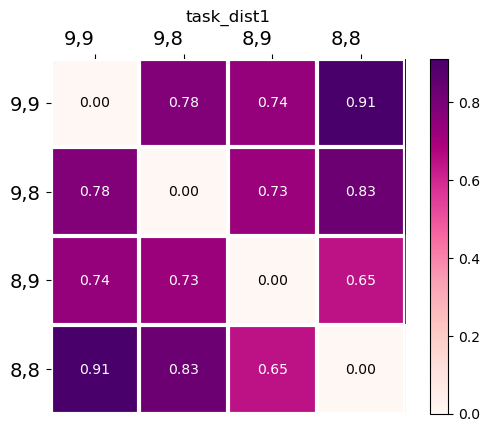

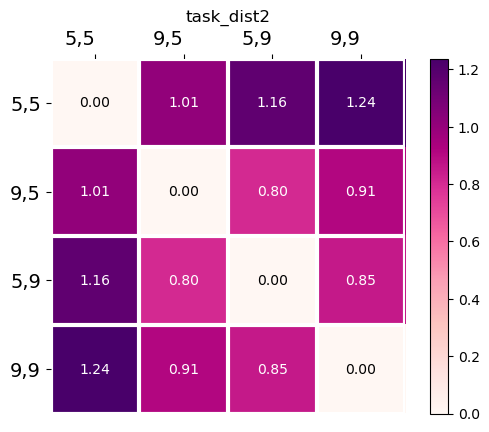

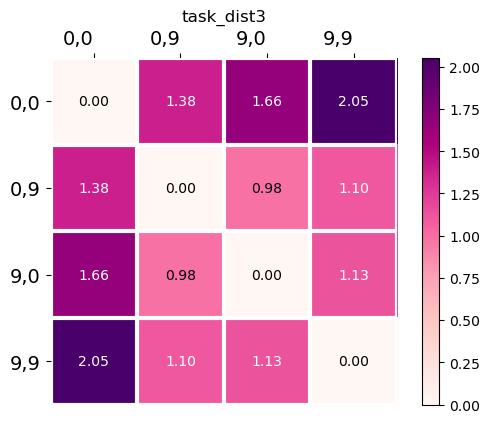

In [10]:
# pairwise L2 heatmap of WTE embeddings (MOSAIC-style)
for i, task_dist in enumerate([task_dist1, task_dist2, task_dist3]):
    OUT_DIR = CODE_DIR / "data" / f"task_dist{i+1}"
    labels = [f"{g[0]},{g[1]}" for g in task_dist]
    embs = [
        np.asarray(detect.lwe(np.load(OUT_DIR / f"goal_{g[0]}_{g[1]}.npy"), ACTION_DIM)).ravel()
        for g in task_dist
    ]
    n = len(embs)
    dist = np.zeros((n, n))
    for a in range(n):
        for b in range(a + 1, n):
            d = np.linalg.norm(embs[a] - embs[b])
            dist[a, b] = dist[b, a] = d

    fig, ax = plt.subplots(figsize=(5, 5))
    im, _ = heatmap(dist, labels, labels, ax=ax, cmap="RdPu")
    annotate_heatmap(im, valfmt="{x:.2f}")
    ax.set_title(f"task_dist{i+1}")
    fig.tight_layout()
    plt.show()